# CellAI — Growth Curve Fits (Round 1, 2, 4)

Two fitting approaches compared:
1. **Fitted offset**: `y = y0 + K / (1 + exp(-r*(t-t0)))` — 4 free parameters (K, r, t0, y0)
2. **Fixed offset**: `y = y0_fixed + K / (1 + exp(-r*(t-t0)))` — 3 free parameters (K, r, t0), y0 = first data point

- **Round 1**: 10 wells (3 SD, 3 HB, 3 LBv2, 1 NB control)
- **Round 2**: 13 wells (4 BayBE HB, 2 BayBE SD, 6 Elnora mechanistic, 1 NB control)
- **Round 4**: 10 wells (3 HBD-Metals, 3 BayBE-HB, 3 Elnora-HB, 1 NB control) — triplicates

In [7]:
import csv
import io
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime
from scipy.optimize import curve_fit

plt.rcParams['figure.figsize'] = (16, 20)
plt.rcParams['font.size'] = 10

In [8]:
# Round 1 raw OD600 data
r1_csv_text = """timestamp,B2,B3,B4,B5,B6,B7,B8,B9,B10,B11
2026-03-15T01:53:06.299872+00:00,0.1606,0.1472,0.1561,0.1355,0.1434,0.1479,0.1155,0.1166,0.1202,0.1224
2026-03-15T02:03:00.596871+00:00,0.1668,0.1542,0.1627,0.1437,0.1507,0.1553,0.1181,0.1193,0.1223,0.1264
2026-03-15T02:12:58.695954+00:00,0.1825,0.1659,0.1741,0.1564,0.1639,0.1682,0.1234,0.1253,0.1271,0.1365
2026-03-15T02:22:58.971090+00:00,0.1999,0.18,0.191,0.1748,0.1813,0.1839,0.1315,0.1336,0.1338,0.1461
2026-03-15T03:03:03.722581+00:00,0.3738,0.3443,0.3639,0.343,0.3435,0.3456,0.2132,0.2475,0.2328,0.2677
2026-03-15T03:12:59.940438+00:00,0.4318,0.3959,0.4232,0.4029,0.4017,0.3934,0.2419,0.2842,0.2704,0.285
2026-03-15T03:23:00.022410+00:00,0.4651,0.4295,0.4635,0.4328,0.4395,0.4477,0.2751,0.3309,0.3156,0.3157
2026-03-15T03:33:02.248492+00:00,0.4852,0.4477,0.4882,0.4455,0.4722,0.4846,0.2994,0.3666,0.3491,0.3297
2026-03-15T03:43:00.457277+00:00,0.4924,0.4581,0.502,0.4545,0.4869,0.5028,0.315,0.3921,0.3751,0.3434
2026-03-15T03:53:00.669364+00:00,0.4961,0.4675,0.5134,0.4622,0.491,0.5153,0.3277,0.4098,0.3958,0.3351
2026-03-15T04:06:52.813051+00:00,0.5049,0.5339,0.5952,0.5393,0.5567,0.5875,0.3966,0.479,0.4541,0.3461
2026-03-15T04:13:07.452103+00:00,0.4972,0.4684,0.5245,0.4714,0.4901,0.5229,0.3369,0.4235,0.4134,0.3528
2026-03-15T04:25:14.281076+00:00,0.5001,0.4664,0.5362,0.474,0.4882,0.5223,0.3446,0.4278,0.4203,0.3567"""

r1_conditions = {
    'B2': ('SD-1', 'YE=7, Tryp=13, MOPS=55mM'),
    'B3': ('SD-2', 'YE=10, Tryp=7, MOPS=35mM'),
    'B4': ('SD-3', 'YE=13, Tryp=10, MOPS=45mM'),
    'B5': ('HB-1', 'YE=7, Tryp=13, NaGl=50mM'),
    'B6': ('HB-2', 'YE=10, Tryp=7, NaGl=30mM'),
    'B7': ('HB-3', 'YE=13, Tryp=10, NaGl=40mM'),
    'B8': ('LB-1', 'MOPS=60, KH2PO4=50, Glu=9'),
    'B9': ('LB-2', 'MOPS=80, KH2PO4=30, Glu=6'),
    'B10': ('LB-3', 'MOPS=90, KH2PO4=40, Glu=4'),
    'B11': ('NB-CTRL', 'Novel Bio Cyclone 180uL'),
}

# Round 2 raw OD600 data
r2_csv_text = """timestamp,B2,B3,B4,B5,B6,B7,B8,D2,D3,D4,D5,D6,D7
2026-03-15T07:31:07.634282+00:00,0.1633,0.1638,0.1632,0.1807,0.161,0.1855,0.1433,0.1627,0.1636,0.2687,0.1419,0.2268,0.1958
2026-03-15T08:06:07.436336+00:00,0.2435,0.2548,0.2564,0.2655,0.2591,0.2806,0.2267,0.2453,0.2544,0.3632,0.2154,0.3208,0.2559
2026-03-15T08:16:02.545981+00:00,0.2585,0.2686,0.2705,0.2764,0.2628,0.2863,0.2501,0.2578,0.2623,0.3688,0.2212,0.3224,0.2472
2026-03-15T08:26:02.876070+00:00,0.2907,0.2977,0.2952,0.3076,0.2835,0.3187,0.2731,0.2904,0.294,0.3871,0.2397,0.3346,0.2627
2026-03-15T08:36:01.479898+00:00,0.3737,0.3478,0.3351,0.3447,0.3116,0.3486,0.2956,0.3378,0.3224,0.4148,0.2601,0.3416,0.2772
2026-03-15T08:46:02.200482+00:00,0.4066,0.4077,0.4085,0.3963,0.3857,0.3993,0.3216,0.3966,0.3831,0.4731,0.3159,0.3526,0.295
2026-03-15T08:56:04.390497+00:00,0.4519,0.4528,0.4557,0.4705,0.4292,0.4754,0.33,0.4534,0.4548,0.5323,0.369,0.3717,0.3228
2026-03-15T09:06:02.545025+00:00,0.4946,0.4933,0.4821,0.5178,0.4702,0.5085,0.3334,0.4783,0.4963,0.5603,0.4132,0.3791,0.3461
2026-03-15T09:16:02.712241+00:00,0.5145,0.5314,0.5194,0.542,0.5106,0.5309,0.3331,0.5062,0.5367,0.5962,0.4565,0.3884,0.3802
2026-03-15T09:26:02.933662+00:00,0.5221,0.5519,0.5358,0.5517,0.5407,0.5538,0.3385,0.5183,0.5532,0.644,0.4924,0.3943,0.4185
2026-03-15T09:36:03.104527+00:00,0.5311,0.5678,0.5534,0.5607,0.5635,0.569,0.3477,0.5234,0.5699,0.6828,0.511,0.3993,0.4492
2026-03-15T09:46:01.332394+00:00,0.5367,0.5728,0.5588,0.5713,0.5738,0.5712,0.356,0.5259,0.5969,0.7047,0.519,0.4047,0.4672
2026-03-15T09:56:01.525291+00:00,0.5386,0.571,0.5573,0.582,0.5759,0.5759,0.3663,0.5254,0.599,0.722,0.5177,0.4079,0.4808"""

r2_conditions = {
    'B2': ('HB-1 (BayBE)', 'YE=5.0, Tryp=14.0, NaGl=50mM'),
    'B3': ('HB-2 (BayBE)', 'YE=8.2, Tryp=11.3, NaGl=50mM'),
    'B4': ('HB-3 (BayBE)', 'YE=8.4, Tryp=14.9, NaGl=50mM'),
    'B5': ('SD-1 (BayBE)', 'YE=15.0, Tryp=10.6, MOPS=47mM'),
    'B6': ('HB-4 (BayBE)', 'YE=6.5, Tryp=12.6, NaGl=40mM'),
    'B7': ('SD-3 (BayBE)', 'YE=12.5, Tryp=8.6, MOPS=55mM'),
    'B8': ('NB-CTL', 'Novel Bio Cyclone 180uL'),
    'D2': ('HBD-MaxN (Elnora)', 'HB+Tryp30+YE20+NaGl15'),
    'D3': ('SD-Glut (Elnora)', 'SD+Tryp26+YE14+NaGl10+MOPS10'),
    'D4': ('HBD-Metals (Elnora)', 'HB+Tryp26+YE14+NaGl10+MgSO4+Trace'),
    'D5': ('HBD-Gly (Elnora)', 'HB+Tryp20+YE14+NaGl10+Glycerol36'),
    'D6': ('HBD-FeCit (Elnora)', 'HB+Tryp26+YE14+NaGl10+FeSO4+NaCit'),
    'D7': ('DefGly-Rich (Elnora)', 'DefGly+Tryp26+YE20+MOPS14'),
}

# Round 4 raw OD600 data (13 reads, triplicates)
r4_csv_text = """timestamp,B2,B3,B4,B5,B6,B7,B8,B9,B10,B11
2026-03-15T21:11:58.060895+00:00,0.4467,0.3394,0.39,0.3271,0.3117,0.2891,0.2784,0.2414,0.2802,0.1872
2026-03-15T21:21:54.048222+00:00,0.4649,0.3462,0.3977,0.3348,0.3199,0.2971,0.2846,0.2458,0.2864,0.2038
2026-03-15T21:31:54.220432+00:00,0.4786,0.3552,0.4114,0.3519,0.336,0.3136,0.2968,0.2598,0.2959,0.2245
2026-03-15T21:41:54.500718+00:00,0.4976,0.366,0.4249,0.371,0.355,0.3329,0.3133,0.2753,0.3106,0.249
2026-03-15T21:51:54.637145+00:00,0.5124,0.3755,0.4394,0.3882,0.3735,0.3523,0.3295,0.2914,0.3258,0.2624
2026-03-15T22:29:59.571514+00:00,0.5688,0.4161,0.502,0.4324,0.4261,0.4061,0.3788,0.3363,0.3729,0.3557
2026-03-15T22:39:57.916823+00:00,0.5795,0.427,0.4996,0.4359,0.4292,0.4078,0.3855,0.3419,0.3777,0.3582
2026-03-15T22:52:08.954195+00:00,0.5792,0.4376,0.504,0.4413,0.4351,0.416,0.3948,0.3524,0.39,0.3652
2026-03-15T23:01:41.297364+00:00,0.5804,0.4457,0.5093,0.4491,0.4403,0.4234,0.402,0.3619,0.3974,0.3709
2026-03-15T23:11:15.137554+00:00,0.5854,0.4495,0.5156,0.4553,0.4469,0.4289,0.4089,0.3699,0.404,0.3765
2026-03-15T23:20:50.600650+00:00,0.5889,0.4537,0.521,0.4605,0.453,0.4347,0.4144,0.3773,0.4087,0.3825
2026-03-15T23:26:54.807005+00:00,0.5836,0.4559,0.5239,0.4631,0.4552,0.4356,0.4204,0.3804,0.4159,0.3863
2026-03-15T23:36:55.033200+00:00,0.5872,0.461,0.5284,0.4672,0.4605,0.4425,0.424,0.3867,0.4201,0.3936"""

r4_conditions = {
    'B2': ('HBD-Metals_1', 'HB122+YE14+Tryp26+NaGl10+MgSO4+Trace'),
    'B3': ('HBD-Metals_2', 'HB122+YE14+Tryp26+NaGl10+MgSO4+Trace'),
    'B4': ('HBD-Metals_3', 'HB122+YE14+Tryp26+NaGl10+MgSO4+Trace'),
    'B5': ('BayBE-HB_1', 'HB110+YE24.7+Tryp15.5+NaGl6.8+Water23'),
    'B6': ('BayBE-HB_2', 'HB110+YE24.7+Tryp15.5+NaGl6.8+Water23'),
    'B7': ('BayBE-HB_3', 'HB110+YE24.7+Tryp15.5+NaGl6.8+Water23'),
    'B8': ('Elnora-HB_1', 'HB110+YE15+Tryp28+NaGl12+Water15'),
    'B9': ('Elnora-HB_2', 'HB110+YE15+Tryp28+NaGl12+Water15'),
    'B10': ('Elnora-HB_3', 'HB110+YE15+Tryp28+NaGl12+Water15'),
    'B11': ('NB-CTL', 'Novel Bio Cyclone 180uL'),
}

In [9]:
def logistic(t, K, r, t0, y0):
    """Logistic with offset: y0 + K / (1 + exp(-r*(t-t0)))"""
    return y0 + K / (1.0 + np.exp(-r * (t - t0)))

def to_unix(ts):
    return datetime.fromisoformat(ts.strip()).timestamp()

def parse_data(csv_text, conditions):
    reader = csv.DictReader(io.StringIO(csv_text))
    wells_data = {}
    for row in reader:
        ts = row['timestamp']
        for well in conditions:
            val = row.get(well, '')
            if val:
                wells_data.setdefault(well, []).append((ts, float(val)))
    return wells_data

def fit_all_fitted_offset(wells_data):
    fit_results = {}
    for well, points in wells_data.items():
        points.sort()
        t0_unix = to_unix(points[0][0])
        times = np.array([(to_unix(ts) - t0_unix) / 3600 for ts, _ in points])
        ods = np.array([od for _, od in points])
        baseline = ods[0]
        K0 = float(np.max(ods) - np.min(ods))
        t0_0 = float(times[np.argmin(np.abs(ods - (np.min(ods) + K0/2)))])
        y0_0 = float(np.min(ods))
        try:
            popt, _ = curve_fit(logistic, times, ods, p0=[K0, 1.0, t0_0, y0_0],
                               bounds=([0, 0, -np.inf, 0], [np.inf, np.inf, np.inf, np.inf]), maxfev=10000)
            K, r, t0, y0 = popt
            y_pred = logistic(times, *popt)
            ss_res = np.sum((ods - y_pred)**2)
            ss_tot = np.sum((ods - np.mean(ods))**2)
            r2 = 1 - ss_res / ss_tot if ss_tot > 0 else None
            fit_results[well] = {'times': times, 'ods': ods, 'popt': popt,
                'K': K, 'r': r, 't0': t0, 'y0': y0, 'r2': r2, 'baseline': baseline, 'biomass_gain': K}
        except Exception as e:
            fit_results[well] = {'times': times, 'ods': ods, 'popt': None,
                'K': None, 'r': None, 't0': None, 'y0': None, 'r2': None, 'baseline': baseline, 'biomass_gain': None, 'error': str(e)}
    return fit_results

def fit_all_fixed_offset(wells_data):
    fit_results = {}
    for well, points in wells_data.items():
        points.sort()
        t0_unix = to_unix(points[0][0])
        times = np.array([(to_unix(ts) - t0_unix) / 3600 for ts, _ in points])
        ods = np.array([od for _, od in points])
        baseline = ods[0]
        K0 = float(np.max(ods) - baseline)
        t0_0 = float(times[np.argmin(np.abs(ods - (baseline + K0/2)))])
        def logistic_fixed(t, K, r, t0):
            return baseline + K / (1.0 + np.exp(-r * (t - t0)))
        try:
            popt, _ = curve_fit(logistic_fixed, times, ods, p0=[K0, 1.0, t0_0],
                               bounds=([0, 0, -np.inf], [np.inf, np.inf, np.inf]), maxfev=10000)
            K, r, t0 = popt
            y_pred = logistic_fixed(times, *popt)
            ss_res = np.sum((ods - y_pred)**2)
            ss_tot = np.sum((ods - np.mean(ods))**2)
            r2 = 1 - ss_res / ss_tot if ss_tot > 0 else None
            full_popt = np.array([K, r, t0, baseline])
            fit_results[well] = {'times': times, 'ods': ods, 'popt': full_popt,
                'K': K, 'r': r, 't0': t0, 'y0': baseline, 'r2': r2, 'baseline': baseline, 'biomass_gain': K}
        except Exception as e:
            fit_results[well] = {'times': times, 'ods': ods, 'popt': None,
                'K': None, 'r': None, 't0': None, 'y0': baseline, 'r2': None, 'baseline': baseline, 'biomass_gain': None, 'error': str(e)}
    return fit_results

all_rounds_data = {
    'R1': (parse_data(r1_csv_text, r1_conditions), r1_conditions),
    'R2': (parse_data(r2_csv_text, r2_conditions), r2_conditions),
    'R4': (parse_data(r4_csv_text, r4_conditions), r4_conditions),
}

all_fits_fitted = {}
all_fits_fixed = {}
for rnd, (wells, conds) in all_rounds_data.items():
    all_fits_fitted[rnd] = (fit_all_fitted_offset(wells), conds)
    all_fits_fixed[rnd] = (fit_all_fixed_offset(wells), conds)

for approach, fits_dict in [("Fitted offset (4 params)", all_fits_fitted), ("Fixed offset (3 params)", all_fits_fixed)]:
    print(f"\n{approach}:")
    for rnd, (fits, _) in fits_dict.items():
        n_tp = len(list(fits.values())[0]['times'])
        note = " (triplicates)" if rnd == 'R4' else ""
        print(f"  {rnd}: {len(fits)} wells, {n_tp} timepoints{note}")


Fitted offset (4 params):
  R1: 10 wells, 13 timepoints
  R2: 13 wells, 13 timepoints
  R4: 10 wells, 13 timepoints (triplicates)

Fixed offset (3 params):
  R1: 10 wells, 13 timepoints
  R2: 13 wells, 13 timepoints
  R4: 10 wells, 13 timepoints (triplicates)


  Fitted Offset


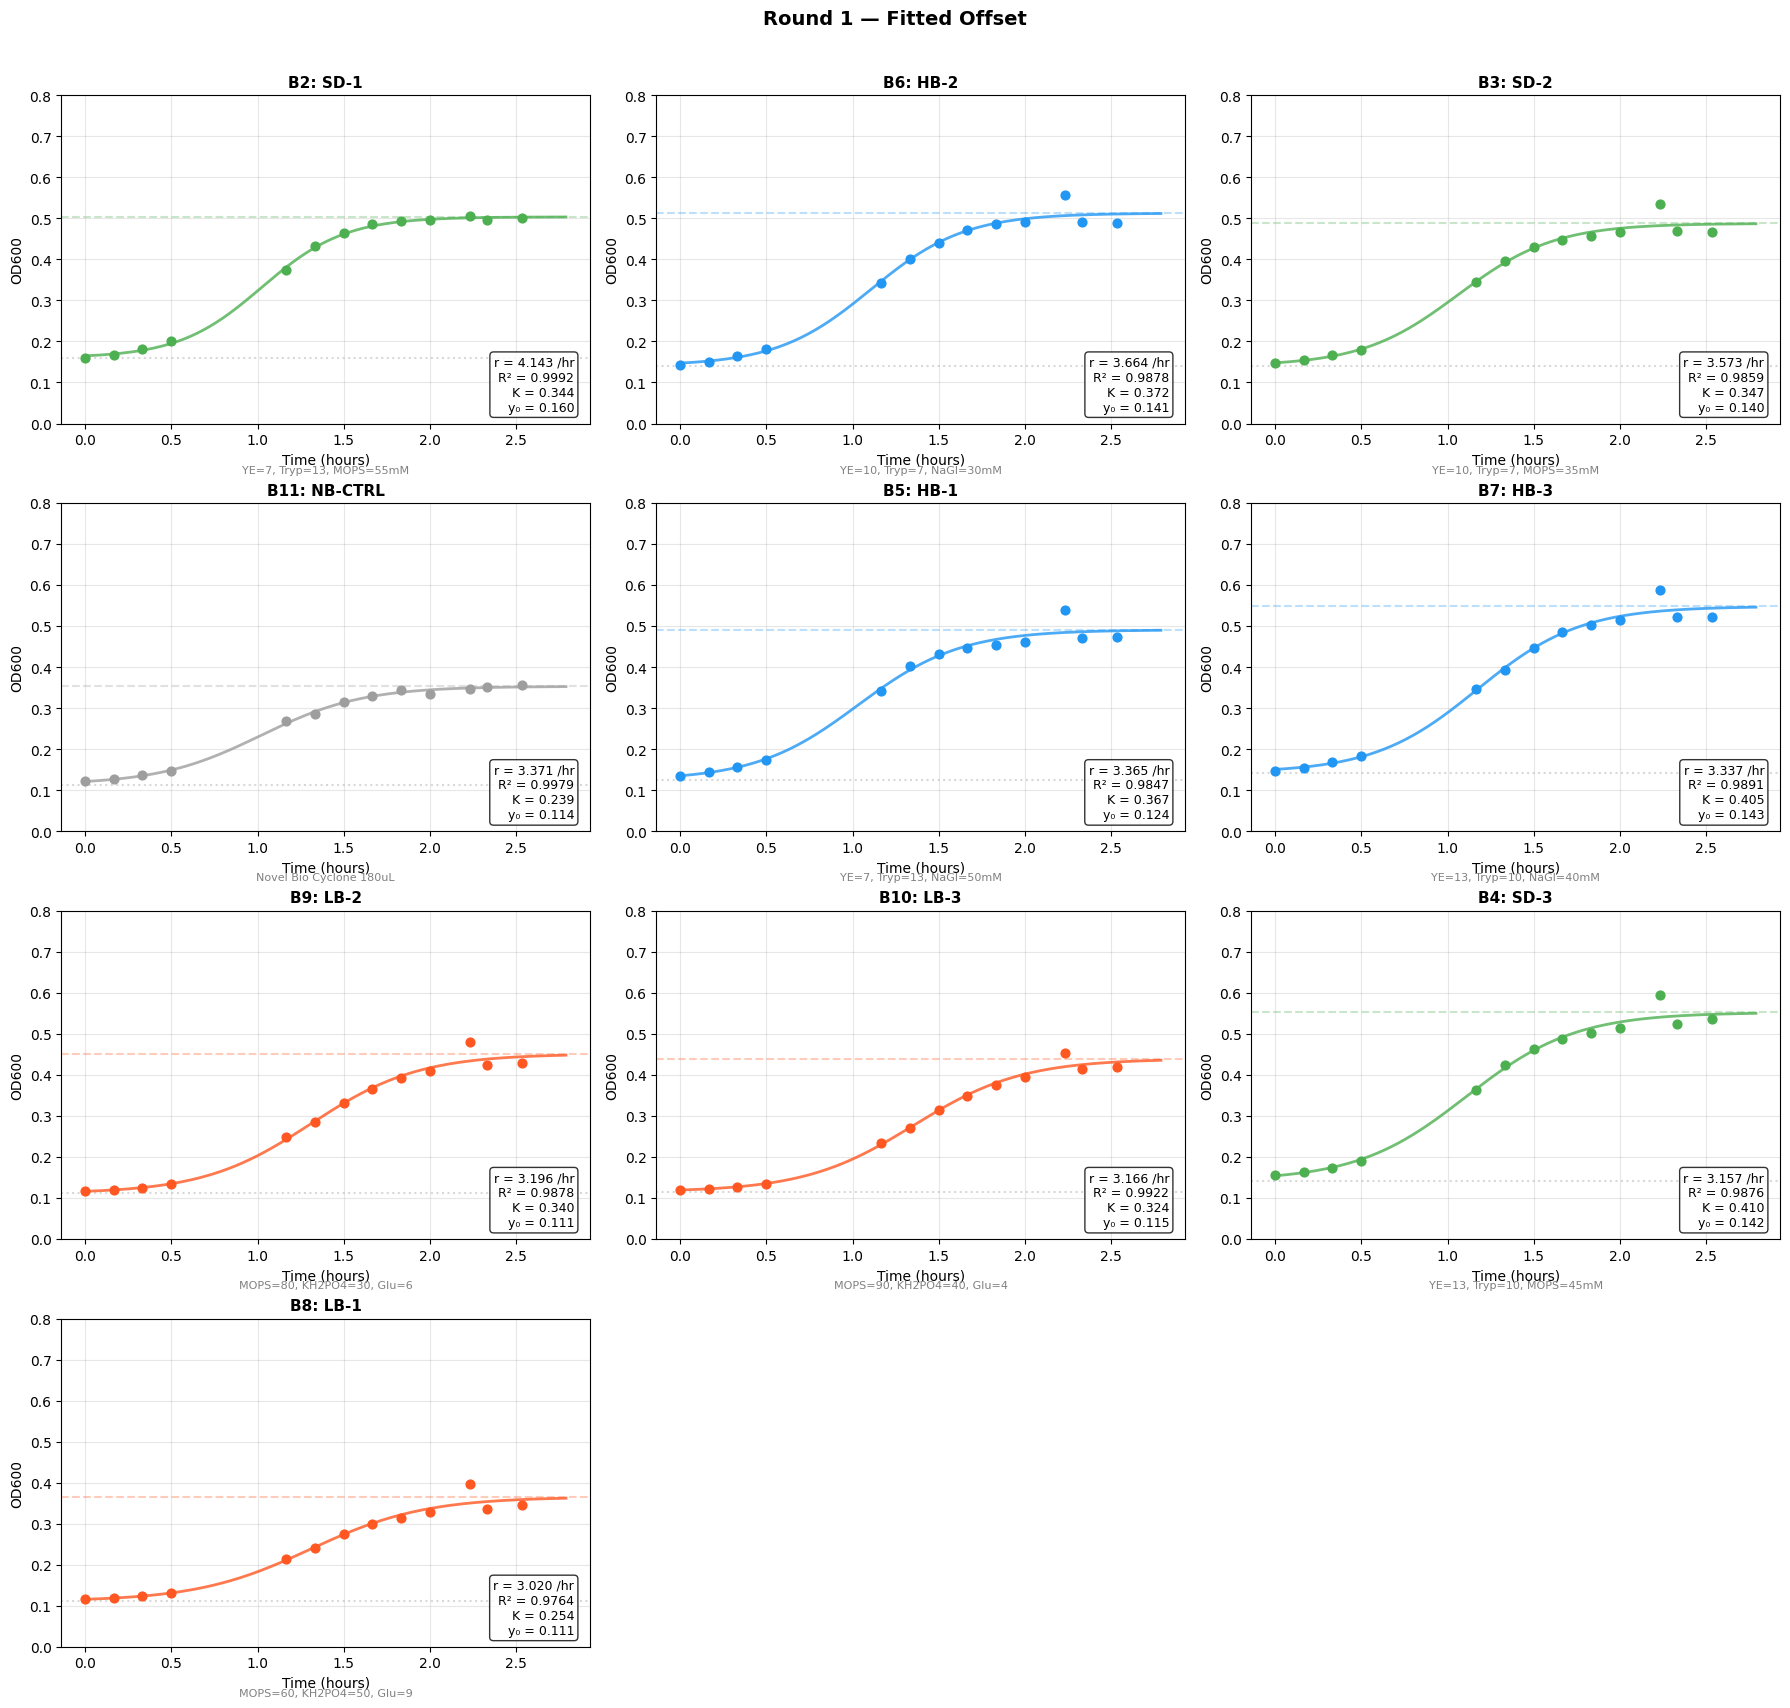

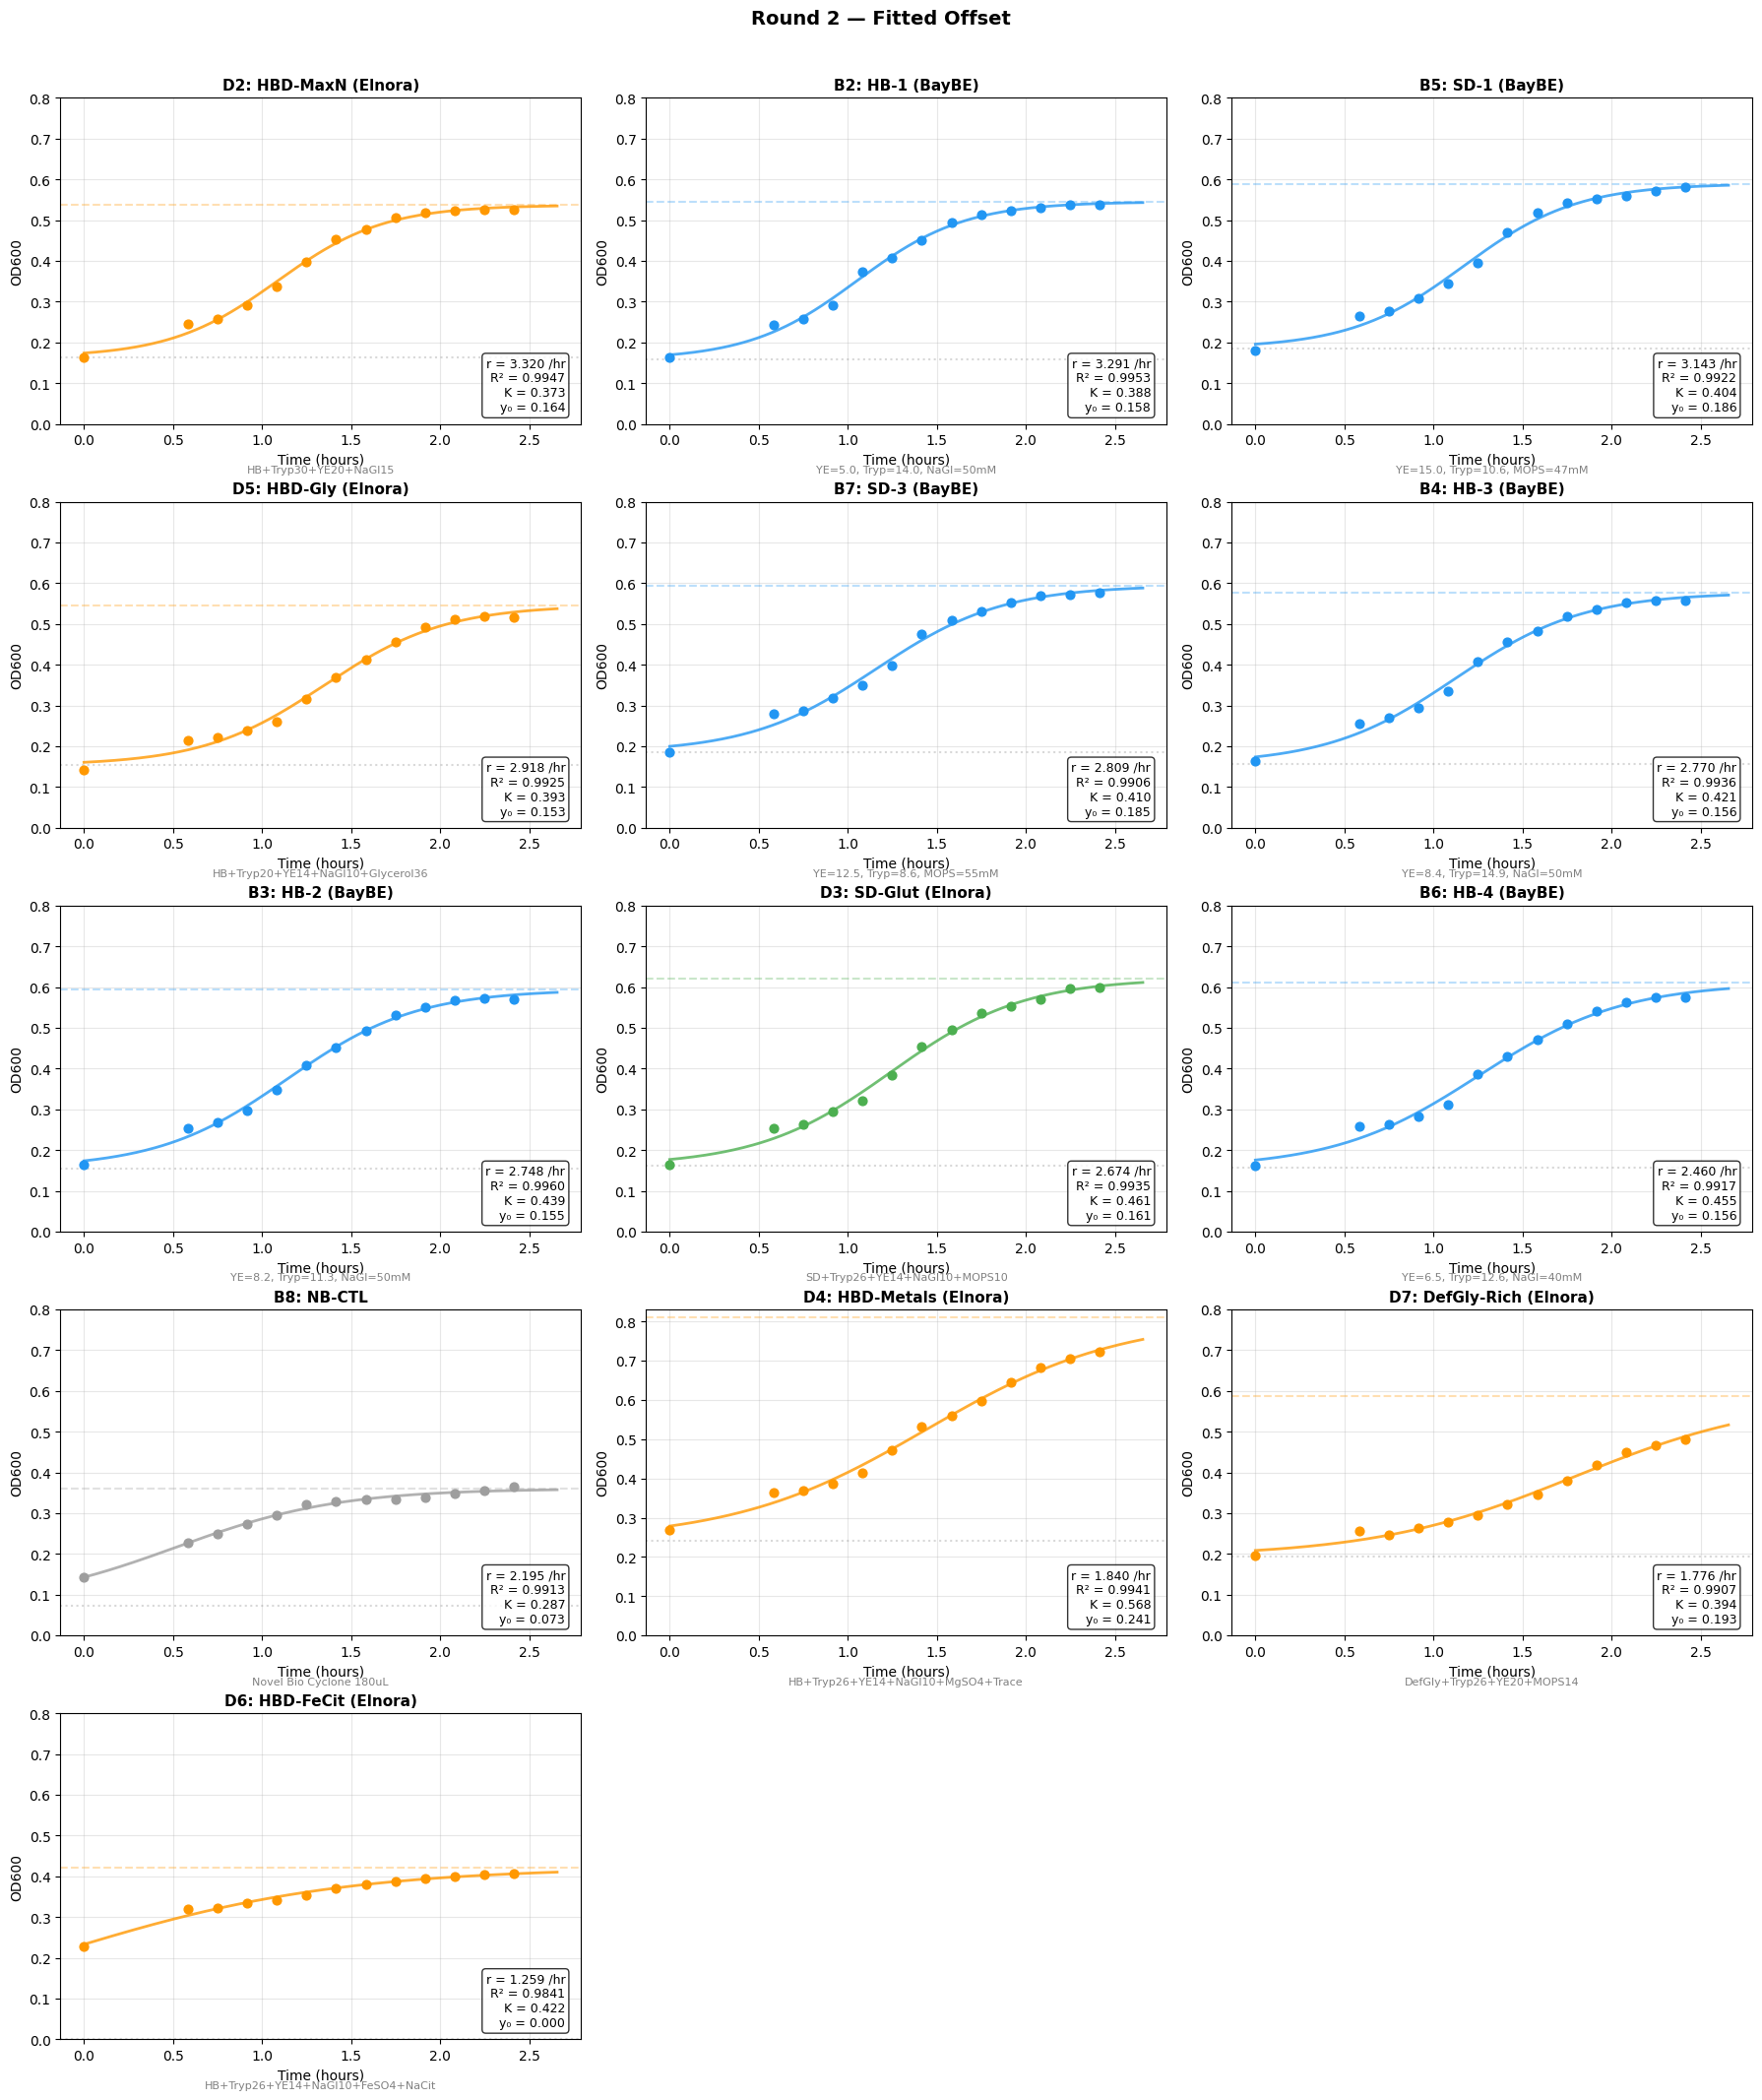

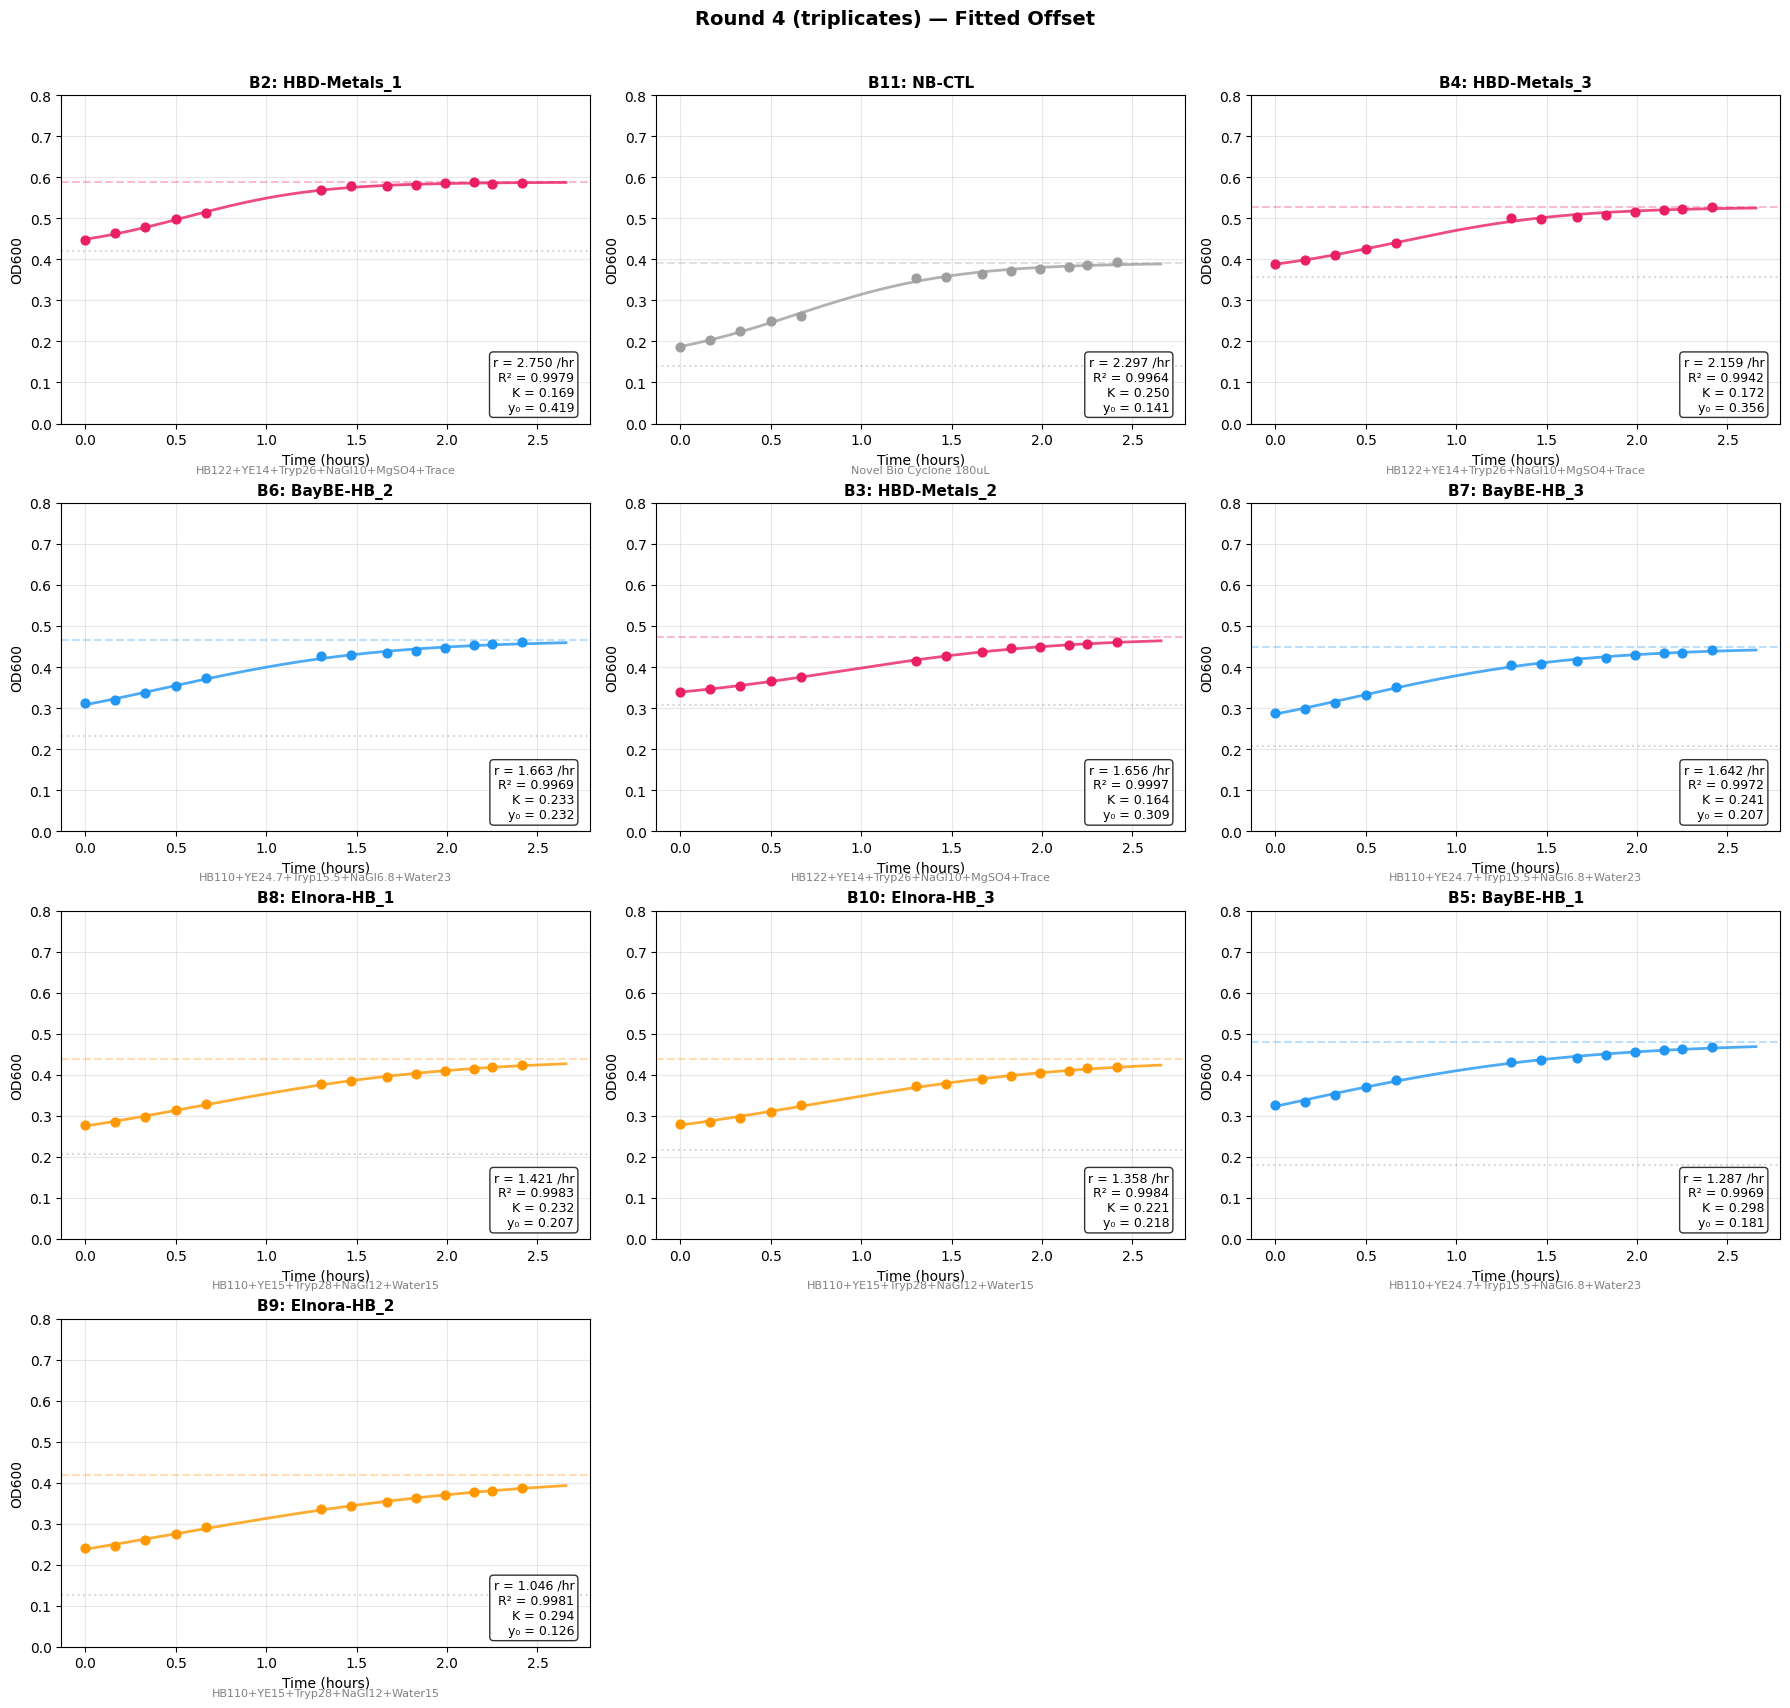

  Fixed Offset


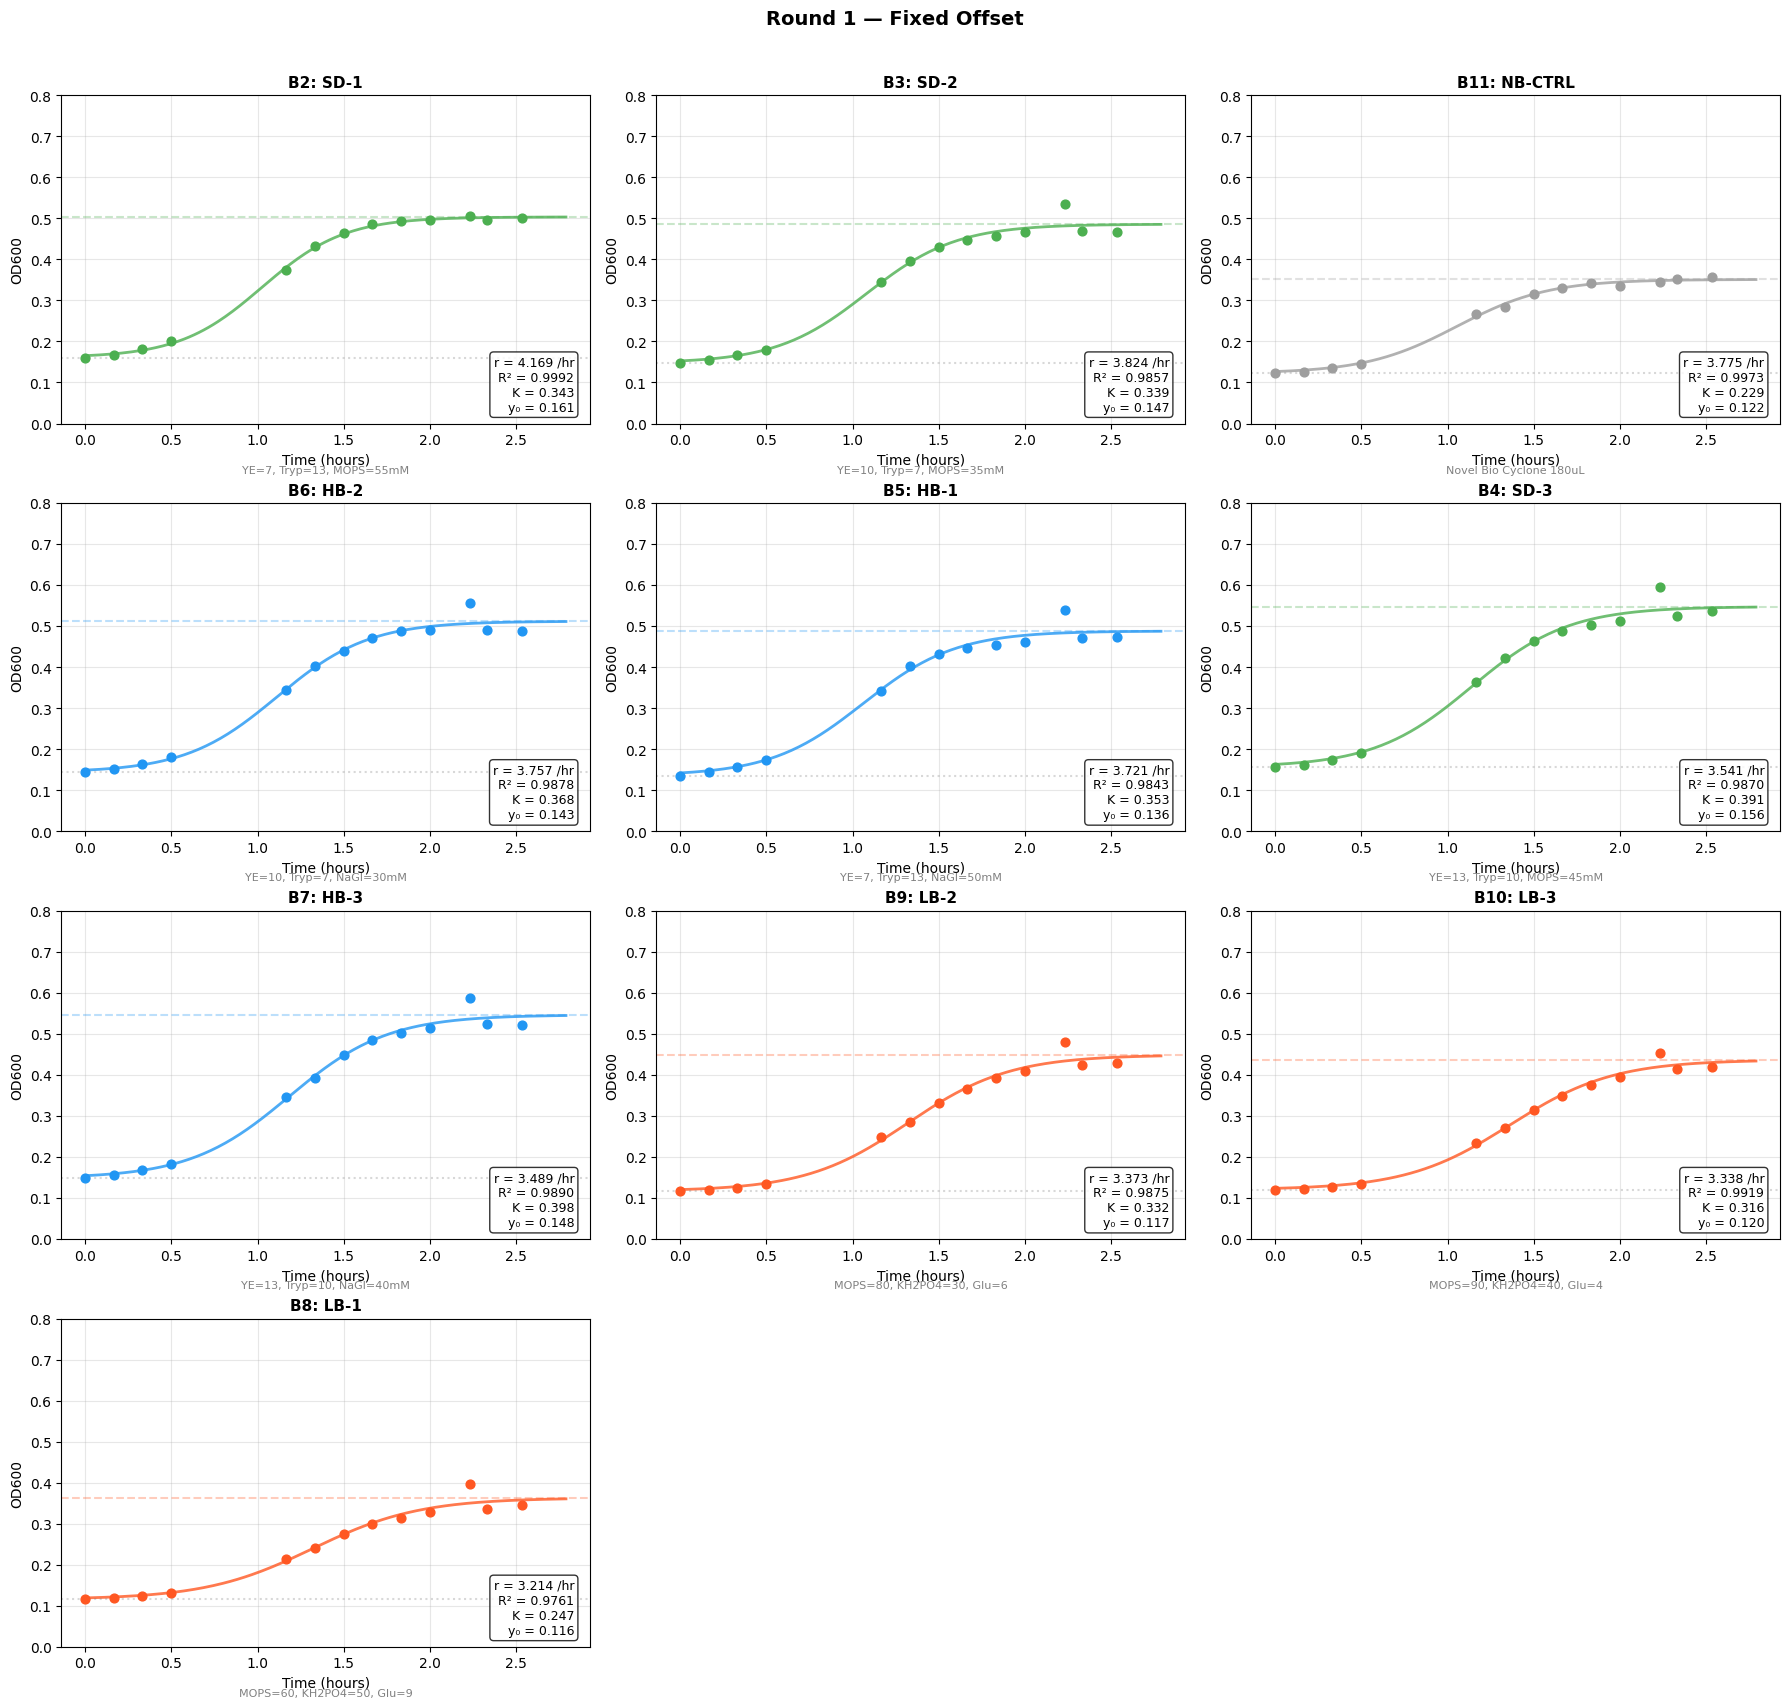

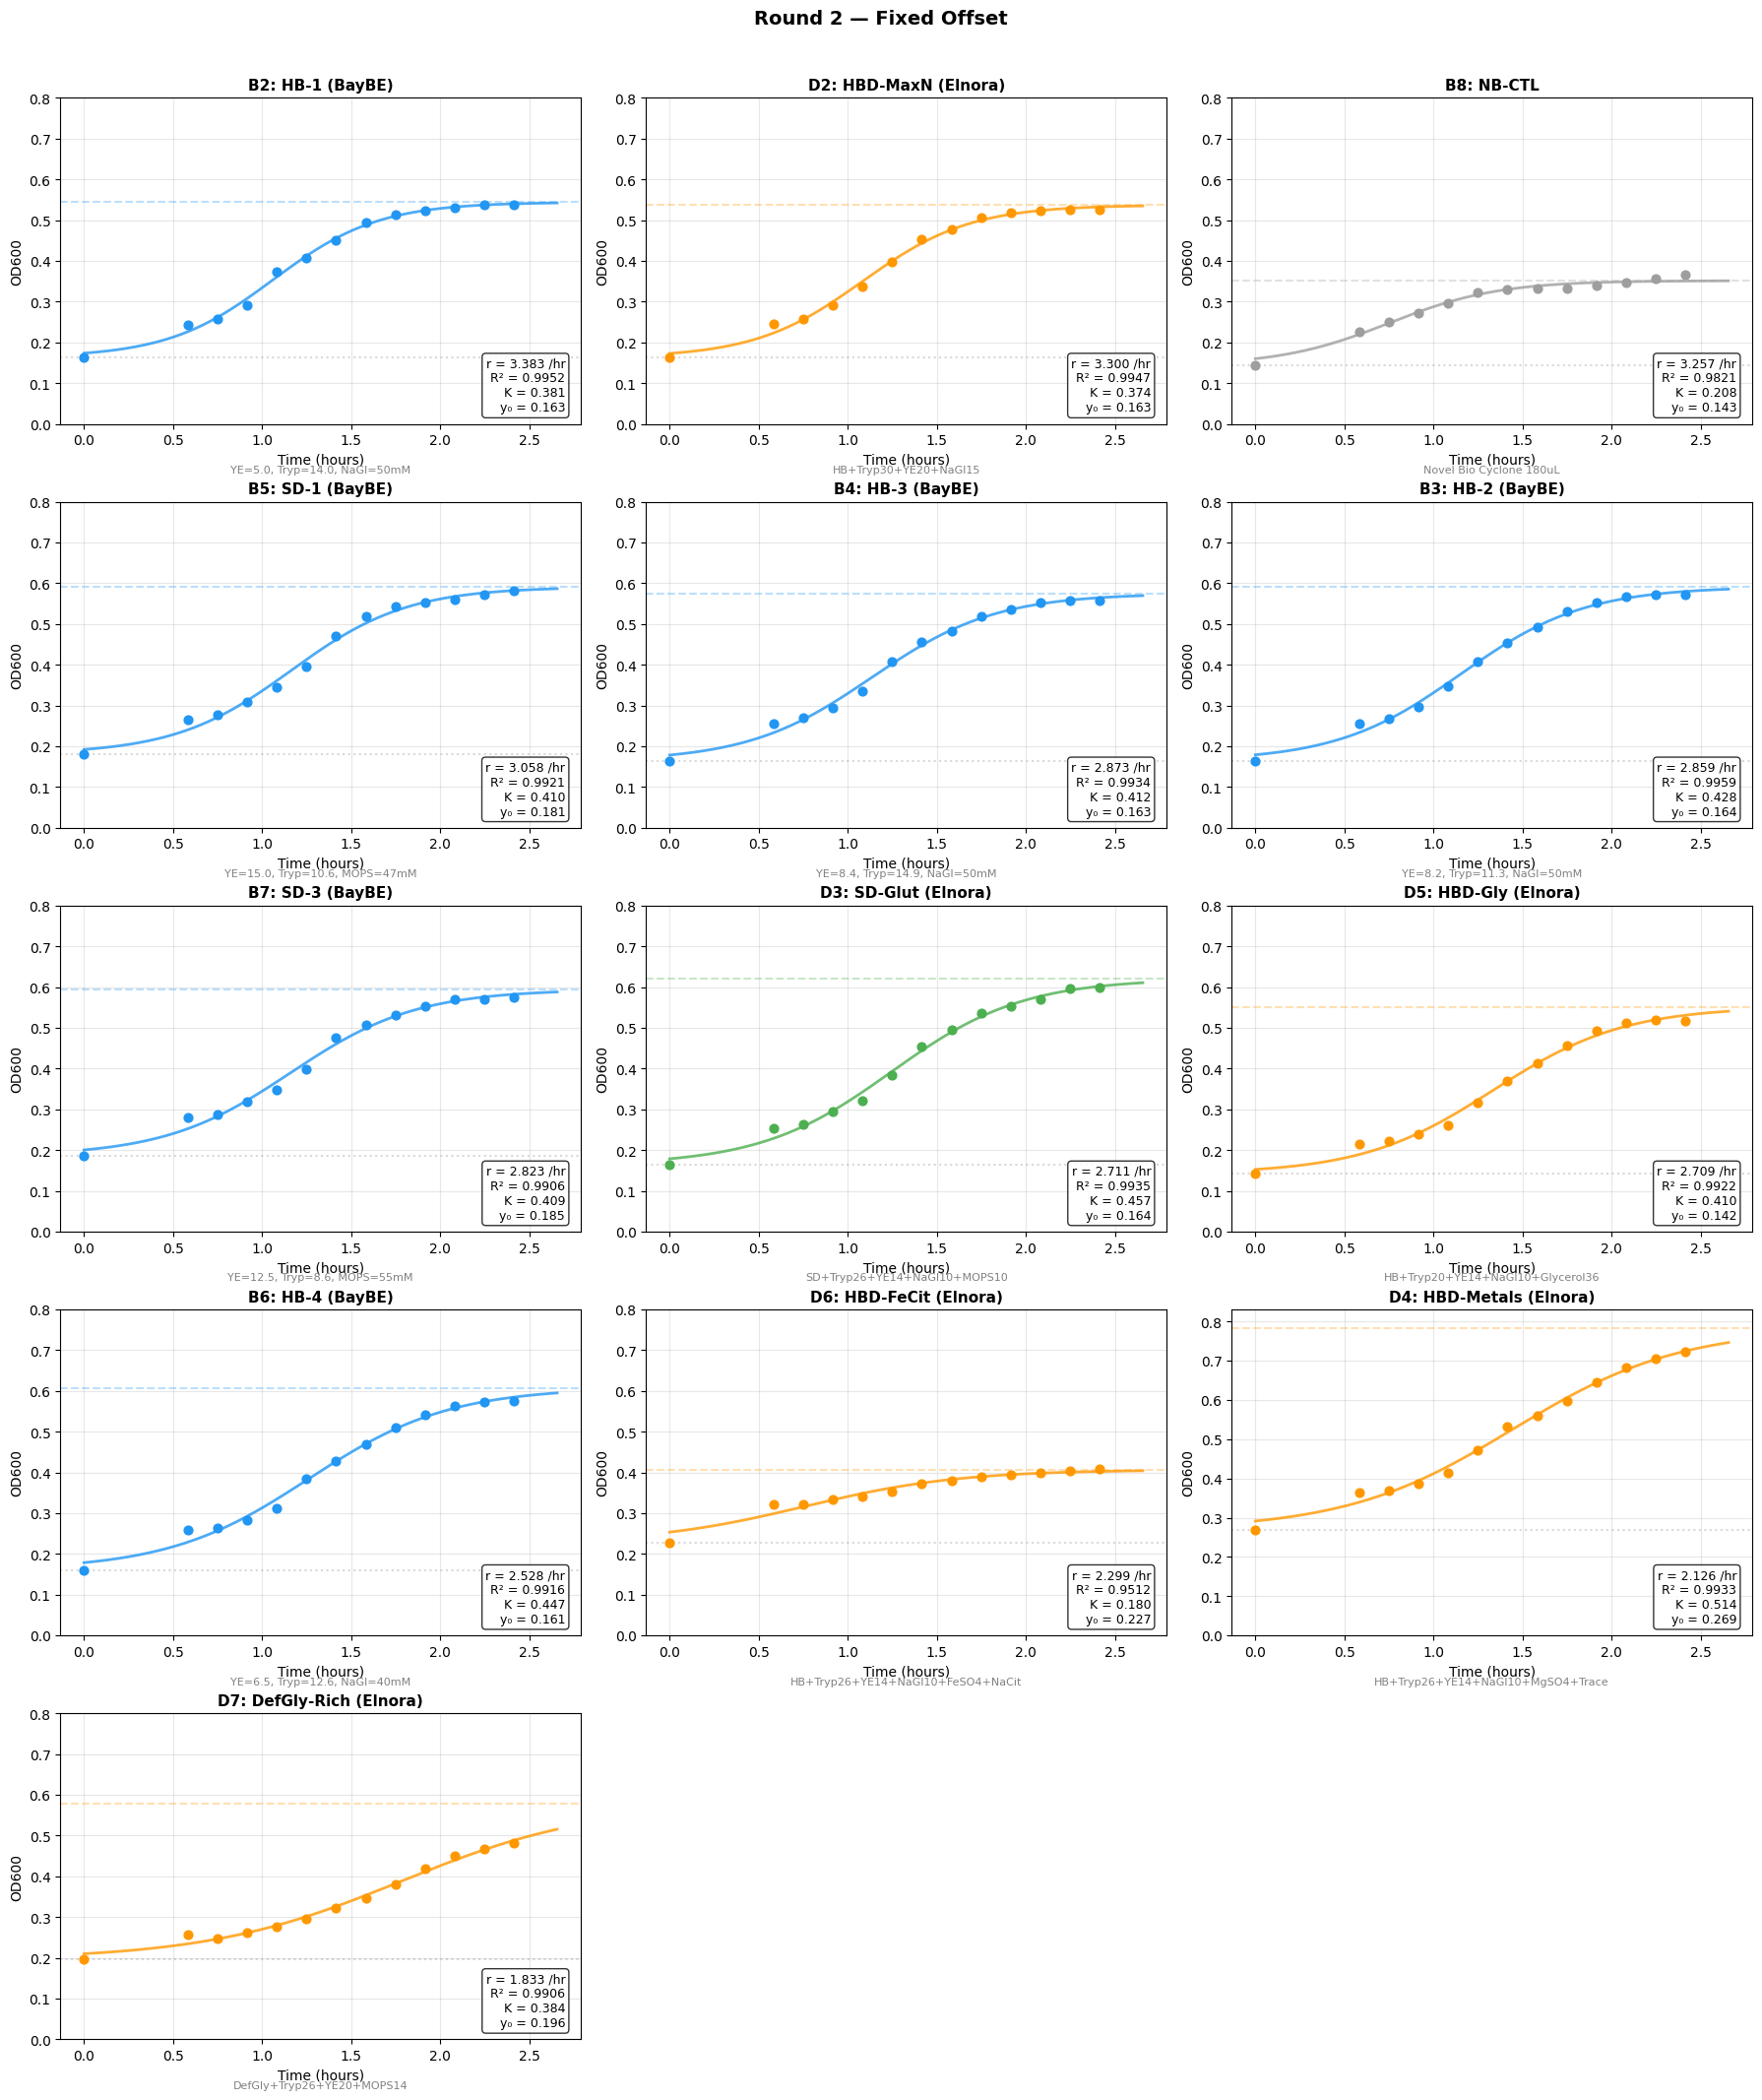

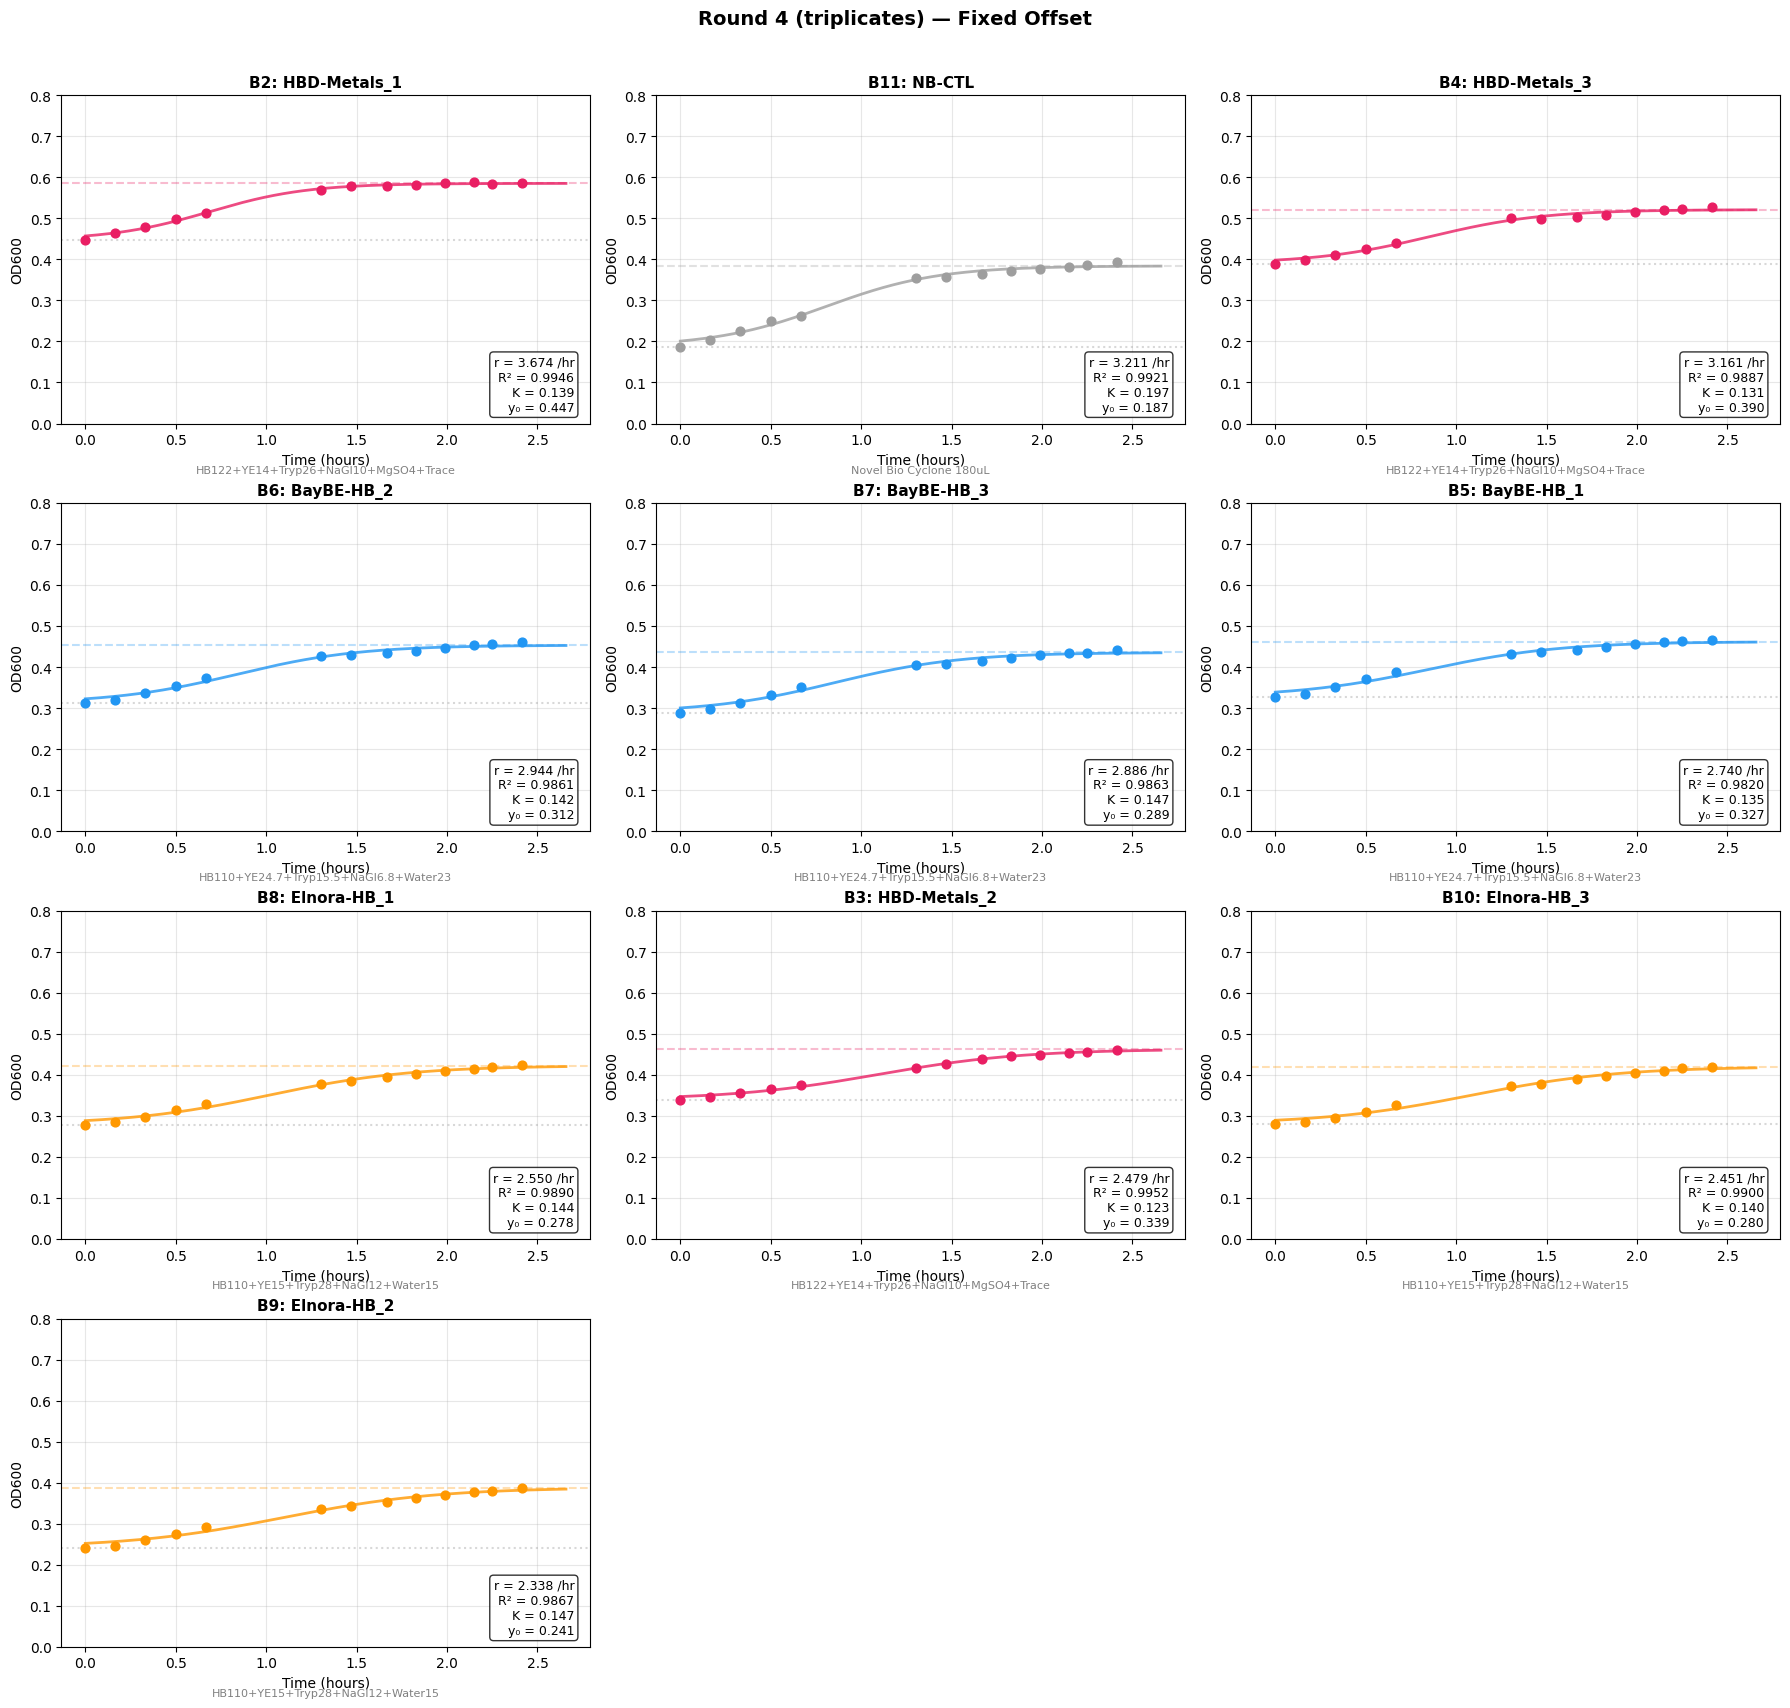

In [10]:
def plot_round(fit_results, conditions, round_name, color_map, approach_name):
    sorted_wells = sorted(fit_results.keys(), key=lambda w: -(fit_results[w]['r'] or 0))
    n = len(sorted_wells)
    ncols = 3
    nrows = (n + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(18, nrows * 4.2))
    axes = axes.flatten()
    for idx, well in enumerate(sorted_wells):
        ax = axes[idx]
        res = fit_results[well]
        cond_name, cond_detail = conditions[well]
        times, ods = res['times'], res['ods']
        color = '#9E9E9E'
        for key, c in color_map.items():
            if key in cond_name: color = c; break
        ax.scatter(times, ods, color=color, s=40, zorder=5)
        if res['popt'] is not None:
            t_smooth = np.linspace(0, max(times) * 1.1, 200)
            y_smooth = logistic(t_smooth, *res['popt'])
            ax.plot(t_smooth, y_smooth, color=color, linewidth=2, alpha=0.8)
            ax.axhline(y=res['y0'] + res['K'], color=color, linestyle='--', alpha=0.3)
            ax.axhline(y=res['y0'], color='gray', linestyle=':', alpha=0.3)
            ax.text(0.97, 0.03, f"r = {res['r']:.3f} /hr\nR² = {res['r2']:.4f}\nK = {res['K']:.3f}\ny₀ = {res['y0']:.3f}",
                    transform=ax.transAxes, fontsize=9, va='bottom', ha='right',
                    bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8))
        ax.set_title(f'{well}: {cond_name}', fontsize=11, fontweight='bold')
        ax.set_xlabel('Time (hours)'); ax.set_ylabel('OD600')
        ax.set_ylim(0, max(0.8, max(ods) * 1.15)); ax.grid(True, alpha=0.3)
        ax.text(0.5, -0.15, cond_detail, transform=ax.transAxes, fontsize=8, ha='center', color='gray')
    for idx in range(n, len(axes)): axes[idx].set_visible(False)
    plt.suptitle(f'{round_name} — {approach_name}', fontsize=14, fontweight='bold', y=1.01)
    plt.tight_layout()
    return fig

color_maps = {
    'R1': {'SD': '#4CAF50', 'HB': '#2196F3', 'LB': '#FF5722', 'NB': '#9E9E9E', 'CTL': '#9E9E9E'},
    'R2': {'BayBE': '#2196F3', 'SD': '#4CAF50', 'Elnora': '#FF9800', 'CTL': '#9E9E9E', 'NB': '#9E9E9E'},
    'R4': {'Metals': '#E91E63', 'BayBE': '#2196F3', 'Elnora': '#FF9800', 'CTL': '#9E9E9E', 'NB': '#9E9E9E'},
}

for approach_name, fits_dict in [('Fitted Offset', all_fits_fitted), ('Fixed Offset', all_fits_fixed)]:
    print("=" * 60)
    print(f"  {approach_name}")
    print("=" * 60)
    for rnd in ['R1', 'R2', 'R4']:
        fits, conds = fits_dict[rnd]
        label = f'Round {rnd[1]}' + (' (triplicates)' if rnd == 'R4' else '')
        fig = plot_round(fits, conds, label, color_maps[rnd], approach_name)
        plt.show()

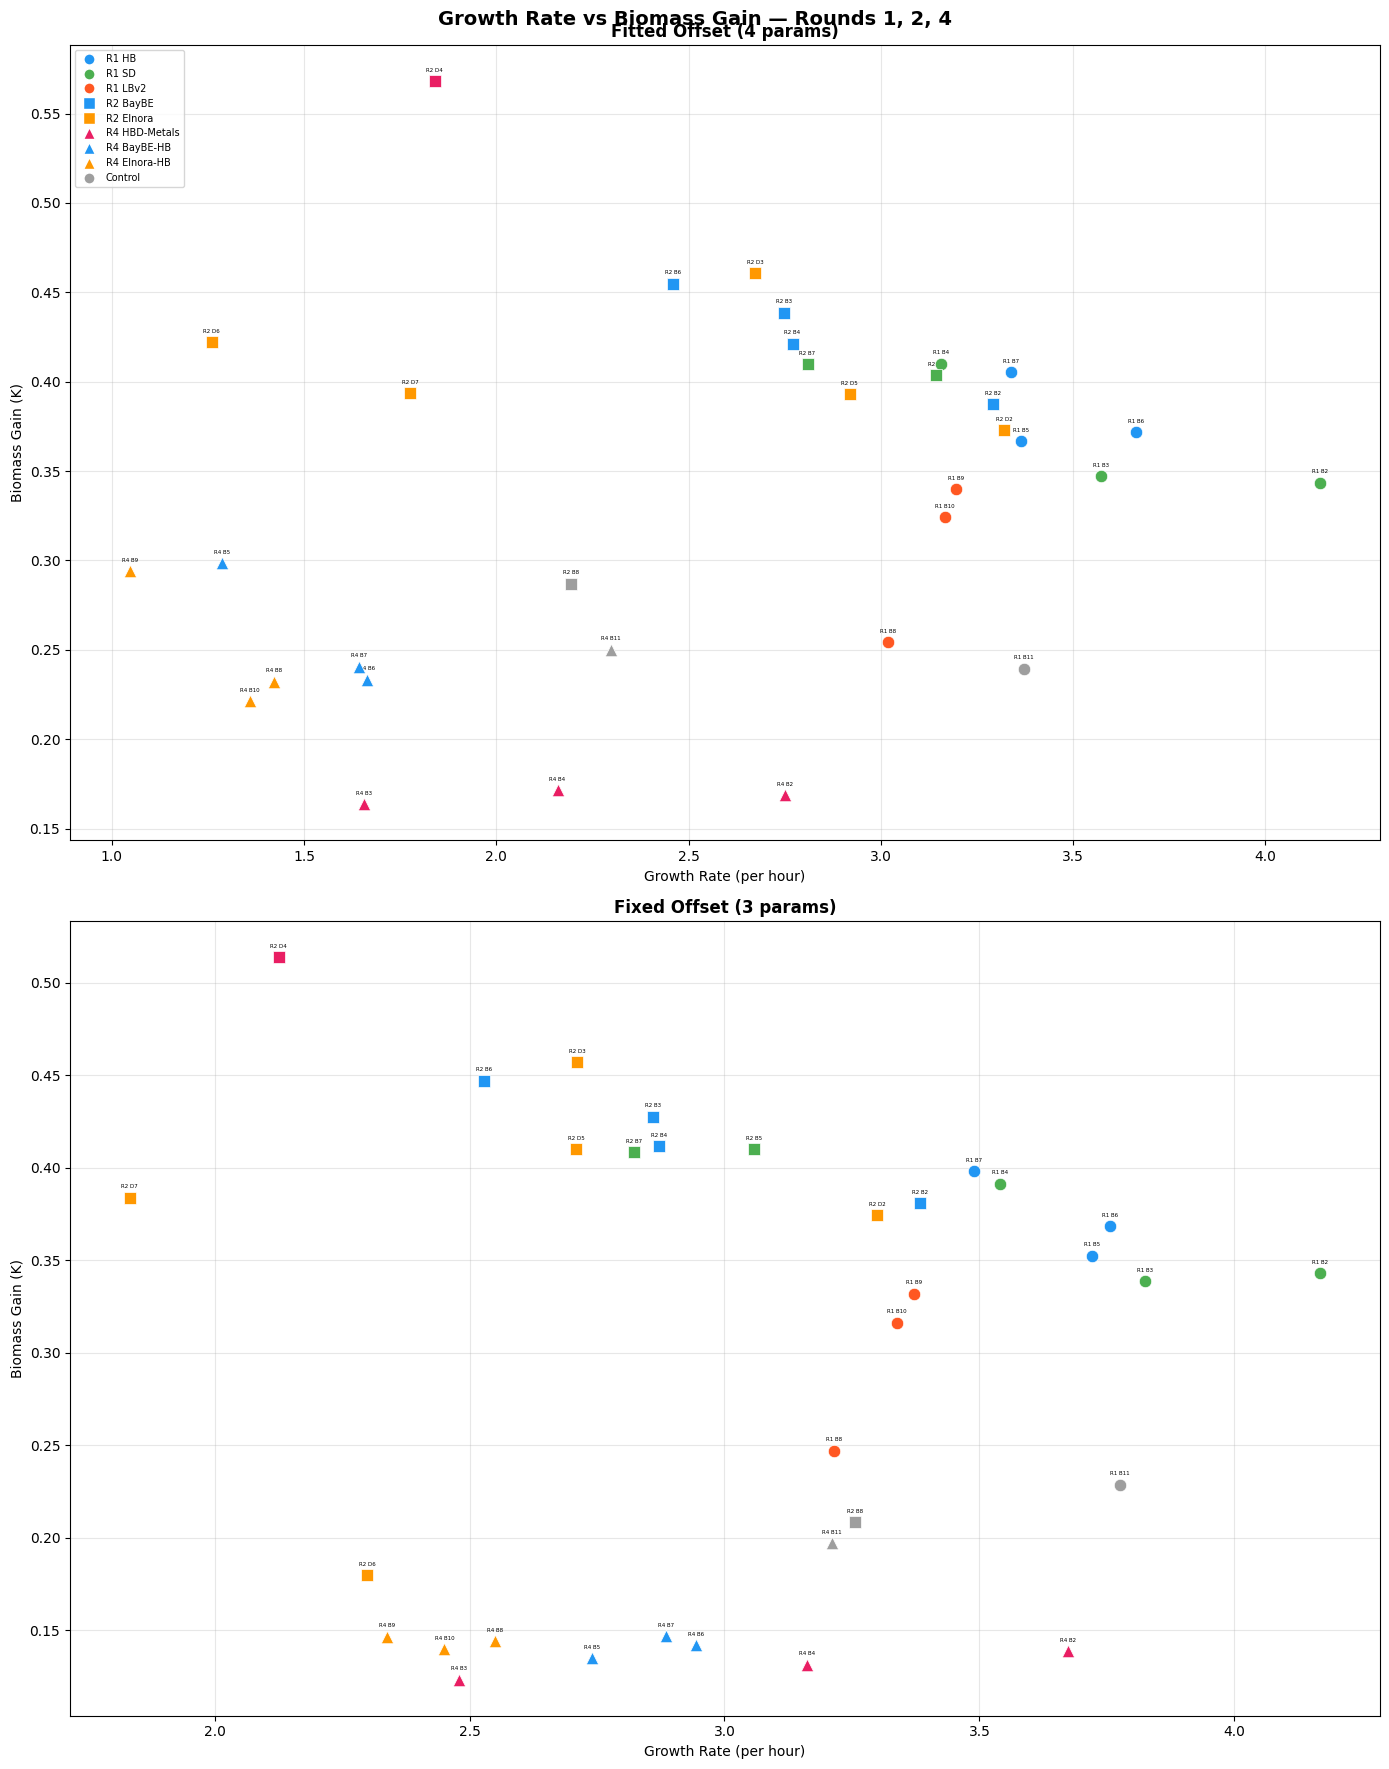

In [11]:
# Combined scatter: R1, R2, R4, stacked by approach
from matplotlib.lines import Line2D

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 18))

markers = {'R1': 'o', 'R2': 's', 'R4': '^'}

for ax, fits_dict, title in [
    (ax1, all_fits_fitted, 'Fitted Offset (4 params)'),
    (ax2, all_fits_fixed, 'Fixed Offset (3 params)'),
]:
    for rnd in ['R1', 'R2', 'R4']:
        fits, conditions = fits_dict[rnd]
        marker = markers[rnd]
        for well in fits:
            res = fits[well]
            cond_name, _ = conditions[well]
            if res['r'] is None or res['biomass_gain'] is None or res['biomass_gain'] > 2:
                continue
            if res['r2'] is not None and res['r2'] < 0:
                continue
            if 'CTL' in cond_name or 'NB' in cond_name:
                color = '#9E9E9E'
            elif 'Metals' in cond_name:
                color = '#E91E63'
            elif 'Elnora' in cond_name:
                color = '#FF9800'
            elif 'LB' in cond_name:
                color = '#FF5722'
            elif 'SD' in cond_name:
                color = '#4CAF50'
            else:
                color = '#2196F3'
            ax.scatter(res['r'], res['biomass_gain'], color=color, s=80, marker=marker,
                       zorder=5, edgecolors='white', linewidth=0.5)
            ax.annotate(f"{rnd} {well}", (res['r'], res['biomass_gain']), fontsize=4,
                        ha='center', va='bottom', xytext=(0, 6), textcoords='offset points')
    ax.set_xlabel('Growth Rate (per hour)')
    ax.set_ylabel('Biomass Gain (K)')
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.grid(True, alpha=0.3)

legend_elements = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#2196F3', markersize=8, label='R1 HB'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#4CAF50', markersize=8, label='R1 SD'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#FF5722', markersize=8, label='R1 LBv2'),
    Line2D([0], [0], marker='s', color='w', markerfacecolor='#2196F3', markersize=8, label='R2 BayBE'),
    Line2D([0], [0], marker='s', color='w', markerfacecolor='#FF9800', markersize=8, label='R2 Elnora'),
    Line2D([0], [0], marker='^', color='w', markerfacecolor='#E91E63', markersize=8, label='R4 HBD-Metals'),
    Line2D([0], [0], marker='^', color='w', markerfacecolor='#2196F3', markersize=8, label='R4 BayBE-HB'),
    Line2D([0], [0], marker='^', color='w', markerfacecolor='#FF9800', markersize=8, label='R4 Elnora-HB'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#9E9E9E', markersize=8, label='Control'),
]
ax1.legend(handles=legend_elements, loc='upper left', fontsize=7)
plt.suptitle('Growth Rate vs Biomass Gain — Rounds 1, 2, 4', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('r124_rate_vs_biomass.png', dpi=150, bbox_inches='tight')
plt.show()

In [12]:
# Combined summary table — R1, R2, R4, both approaches
import pandas as pd

rows = []
for approach, fits_dict in [('Fitted Offset', all_fits_fitted), ('Fixed Offset', all_fits_fixed)]:
    for rnd in ['R1', 'R2', 'R4']:
        fits, conditions = fits_dict[rnd]
        for well in sorted(fits.keys(), key=lambda w: -(fits[w]['r'] or 0)):
            res = fits[well]
            cond_name, _ = conditions[well]
            max_od_bg = round(max(res['ods']) - res['baseline'], 4)
            rows.append({
                'Approach': approach, 'Round': rnd, 'Well': well, 'Condition': cond_name,
                'r (/hr)': round(res['r'], 4) if res['r'] else None,
                'K (dOD)': round(res['K'], 4) if res['K'] else None,
                'y0': round(res['y0'], 4) if res['y0'] else None,
                'Max OD (bg-sub)': max_od_bg,
                'R²': round(res['r2'], 4) if res['r2'] else None,
            })

df = pd.DataFrame(rows)

for rnd in ['R1', 'R2', 'R4']:
    note = ' (triplicates)' if rnd == 'R4' else ''
    print(f"\n{'='*60}")
    print(f"  {rnd}{note}")
    print(f"{'='*60}")
    sub = df[df['Round'] == rnd].pivot_table(
        index=['Well', 'Condition'],
        columns='Approach',
        values=['r (/hr)', 'K (dOD)', 'Max OD (bg-sub)', 'R²'],
        aggfunc='first'
    )
    display(sub.sort_values(('r (/hr)', 'Fixed Offset'), ascending=False))


  R1


K (dOD)              Max OD (bg-sub)               \
Approach       Fitted Offset Fixed Offset   Fitted Offset Fixed Offset   
Well Condition                                                           
B2   SD-1             0.3436       0.3429          0.3443       0.3443   
B3   SD-2             0.3472       0.3386          0.3867       0.3867   
B11  NB-CTRL          0.2393       0.2288          0.2343       0.2343   
B6   HB-2             0.3718       0.3685          0.4133       0.4133   
B5   HB-1             0.3667       0.3525          0.4038       0.4038   
B4   SD-3             0.4101       0.3914          0.4391       0.4391   
B7   HB-3             0.4052       0.3983          0.4396       0.4396   
B9   LB-2             0.3400       0.3320          0.3624       0.3624   
B10  LB-3             0.3240       0.3163          0.3339       0.3339   
B8   LB-1             0.2541       0.2471          0.2811       0.2811   

                          R²                    r (/hr)               
Approach       Fitted Offset Fixed Offset Fitted Offset Fixed Offset  
Well Condition                                                        
B2   SD-1             0.9992       0.9992        4.1433       4.1689  
B3   SD-2             0.9859       0.9857        3.5726       3.8243  
B11  NB-CTRL          0.9979       0.9973        3.3715       3.7751  
B6   HB-2             0.9878       0.9878        3.6640       3.7571  
B5   HB-1             0.9847       0.9843        3.3651       3.7209  
B4   SD-3             0.9876       0.9870        3.1568       3.5412  
B7   HB-3             0.9891       0.9890        3.3374       3.4892  
B9   LB-2             0.9878       0.9875        3.1960       3.3726  
B10  LB-3             0.9922       0.9919        3.1656       3.3385  
B8   LB-1             0.9764       0.9761        3.0196       3.2144


  R2


K (dOD)              Max OD (bg-sub)  \
Approach                  Fitted Offset Fixed Offset   Fitted Offset   
Well Condition                                                         
B2   HB-1 (BayBE)                0.3875       0.3808          0.3753   
D2   HBD-MaxN (Elnora)           0.3730       0.3744          0.3632   
B8   NB-CTL                      0.2870       0.2082          0.2230   
B5   SD-1 (BayBE)                0.4037       0.4103          0.4013   
B4   HB-3 (BayBE)                0.4212       0.4116          0.3956   
B3   HB-2 (BayBE)                0.4386       0.4276          0.4090   
B7   SD-3 (BayBE)                0.4098       0.4086          0.3904   
D3   SD-Glut (Elnora)            0.4609       0.4570          0.4354   
D5   HBD-Gly (Elnora)            0.3930       0.4101          0.3771   
B6   HB-4 (BayBE)                0.4548       0.4470          0.4149   
D6   HBD-FeCit (Elnora)          0.4221       0.1797          0.1811   
D4   HBD-Metals (Elnora)         0.5680       0.5140          0.4533   
D7   DefGly-Rich (Elnora)        0.3937       0.3838          0.2850   

                                                  R²               \
Approach                  Fixed Offset Fitted Offset Fixed Offset   
Well Condition                                                      
B2   HB-1 (BayBE)               0.3753        0.9953       0.9952   
D2   HBD-MaxN (Elnora)          0.3632        0.9947       0.9947   
B8   NB-CTL                     0.2230        0.9913       0.9821   
B5   SD-1 (BayBE)               0.4013        0.9922       0.9921   
B4   HB-3 (BayBE)               0.3956        0.9936       0.9934   
B3   HB-2 (BayBE)               0.4090        0.9960       0.9959   
B7   SD-3 (BayBE)               0.3904        0.9906       0.9906   
D3   SD-Glut (Elnora)           0.4354        0.9935       0.9935   
D5   HBD-Gly (Elnora)           0.3771        0.9925       0.9922   
B6   HB-4 (BayBE)               0.4149        0.9917       0.9916   
D6   HBD-FeCit (Elnora)         0.1811        0.9841       0.9512   
D4   HBD-Metals (Elnora)        0.4533        0.9941       0.9933   
D7   DefGly-Rich (Elnora)       0.2850        0.9907       0.9906   

                                r (/hr)               
Approach                  Fitted Offset Fixed Offset  
Well Condition                                        
B2   HB-1 (BayBE)                3.2915       3.3827  
D2   HBD-MaxN (Elnora)           3.3204       3.2998  
B8   NB-CTL                      2.1946       3.2569  
B5   SD-1 (BayBE)                3.1434       3.0585  
B4   HB-3 (BayBE)                2.7702       2.8726  
B3   HB-2 (BayBE)                2.7480       2.8592  
B7   SD-3 (BayBE)                2.8092       2.8230  
D3   SD-Glut (Elnora)            2.6736       2.7112  
D5   HBD-Gly (Elnora)            2.9184       2.7088  
B6   HB-4 (BayBE)                2.4596       2.5283  
D6   HBD-FeCit (Elnora)          1.2593       2.2988  
D4   HBD-Metals (Elnora)         1.8397       2.1255  
D7   DefGly-Rich (Elnora)        1.7759       1.8332


  R4 (triplicates)


K (dOD)              Max OD (bg-sub)               \
Approach          Fitted Offset Fixed Offset   Fitted Offset Fixed Offset   
Well Condition                                                              
B2   HBD-Metals_1        0.1687       0.1386          0.1422       0.1422   
B11  NB-CTL              0.2500       0.1970          0.2064       0.2064   
B4   HBD-Metals_3        0.1715       0.1313          0.1384       0.1384   
B6   BayBE-HB_2          0.2334       0.1418          0.1488       0.1488   
B7   BayBE-HB_3          0.2406       0.1467          0.1534       0.1534   
B5   BayBE-HB_1          0.2984       0.1349          0.1401       0.1401   
B8   Elnora-HB_1         0.2321       0.1441          0.1456       0.1456   
B3   HBD-Metals_2        0.1637       0.1233          0.1216       0.1216   
B10  Elnora-HB_3         0.2213       0.1399          0.1399       0.1399   
B9   Elnora-HB_2         0.2938       0.1466          0.1453       0.1453   

                             R²                    r (/hr)               
Approach          Fitted Offset Fixed Offset Fitted Offset Fixed Offset  
Well Condition                                                           
B2   HBD-Metals_1        0.9979       0.9946        2.7495       3.6744  
B11  NB-CTL              0.9964       0.9921        2.2972       3.2111  
B4   HBD-Metals_3        0.9942       0.9887        2.1590       3.1611  
B6   BayBE-HB_2          0.9969       0.9861        1.6631       2.9443  
B7   BayBE-HB_3          0.9972       0.9863        1.6421       2.8863  
B5   BayBE-HB_1          0.9969       0.9820        1.2867       2.7395  
B8   Elnora-HB_1         0.9983       0.9890        1.4209       2.5496  
B3   HBD-Metals_2        0.9997       0.9952        1.6563       2.4792  
B10  Elnora-HB_3         0.9984       0.9900        1.3582       2.4509  
B9   Elnora-HB_2         0.9981       0.9867        1.0460       2.3384